# 3. Entrainement du model de classification des images


Dans ce troisieme etape, on va monter et entrainer un model de classification en utilisant les images train. On va tourner ce modele plusieurs fois et on va garder le meilleur resulat obtenu parmis les runs faites. Pour le choix de modele on a choisi d'utiliser le modele **EfficientNetV2‑S**. Cette etape est la seule etape qui va pas tourner dans la machine local, mais sur kaggle a cause des resources neccesaires pour entrainer le modele (GPU avec CUDA). C'est pour ca qu'une fois le notebook est fini, on va exporter et telecharger depuis kaggle la configuration du meilleur modele trouve pour l'utiliser dans la prochaine etape de prediction (Qui va tourner localement)

Celui ci est la version 2 du modele. Precedament un autre modele a ete teste et a donnee des resultats legerements pires que celui ci. Le premiere modele teste ete un EfficientNet‑B0 qui est un modele plus petit et facil a tourner, mais aussi moins puissant

On a aussi certain elections importantes a faire: 
1. Modele a utiliser: **EfficientNetV2‑S** est un bon modele pour classifier les images
2. Train/validation split **by patient** (`StratifiedGroupKFold`): both eyes of a patient are very correlated, so they must stay in the same set to avoid leakage.
3. **Regression** (1 output + MSE) instead of 5‑class classification: the levels are ordered, and the error 0→4 must cost more than 0→1.
4. Scores converted to levels by **matching the train distribution**, and model selection on the **quadratic weighted kappa (QWK)**.

Comme resultat final, on a trouve un meilleur modele avec un QWK = 0.8219 (epoch 8)

## Libraries

In [ ]:
import pandas as pd
import os
from glob import glob
import matplotlib.pyplot as plt
import cv2
import numpy as np
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import cohen_kappa_score
import json


## GPU to use
Vu la nature de notre projet, on veut utiliser une carte grapique puissante pour entrainer notre modele. Kaggle peut nous fournir de ca, donc on va s'assurer qu'on utilise la bon carte graphique avant de continuer

In [ ]:
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_capability(0))


Tesla T4
(7, 5)


# Preprocessed data

## Load preprocessed data

In [25]:
# Load csv and transform it
file_lbl="/kaggle/input/diabetic-retinopathy-detection/trainLabels.csv.zip"
df_train_edited_full = pd.read_csv(file_lbl,sep=',')
df_train_edited_full

df_train_edited_full["image"] = df_train_edited_full["image"]+"_edited"
df_train_edited_full


,image,level
0,10_left_edited,0
1,10_right_edited,0
2,13_left_edited,0
3,13_right_edited,0
4,15_left_edited,1
...,...,...
35121,44347_right_edited,0
35122,44348_left_edited,0
35123,44348_right_edited,0
35124,44349_left_edited,0


Un chose important a noter c'est que on a des images des patients qui vient en pairs, donc c'est important de checker et travailler avec les images des deux yeux par patient dans le meme group (soit train soit validation) car elles sont fortement correles entres eux. Si on ne le fait pas on risque d'avoir un probleme de leakage.

In [26]:
#Patient id: "10_left_edited" -> "10". Both eyes of the same patient share the same id.
df_train_edited_full["patient_id"] = df_train_edited_full["image"].str.split("_").str[0]

print("Number of images  :", len(df_train_edited_full))
print("Number of patients:", df_train_edited_full["patient_id"].nunique())
# Most patients should have exactly 2 images (left + right eye)
print(df_train_edited_full.groupby("patient_id").size().value_counts())

Number of images  : 35126
Number of patients: 17563
2    17563
Name: count, dtype: int64


Juste en mesure de securite, on peut afficher la premiere image du group pour s'assurer qu'on a bien les images transformes et standarises et pas les images brutes

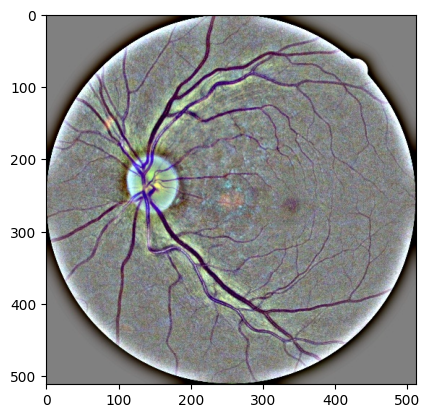

In [27]:
# Show first image
paths_train_edited = glob('/kaggle/input/datasets/jullopz/retinoplathy-detection-edited-v1/edited/*.jpeg')
image=cv2.imread(paths_train_edited[0])
plt.imshow(image)

## Apply transformation to preprocessed images

En plus des transformations faites dans le preprocessing dans l'etape precedente, on veut appliquer des transformations supplementaires aux images pour mieux entrainer notre modele. L'idee de ca c'est de entrainer un modele plus robuste qui sait gerer des images legerement differentes, on veut:
1. reduce overfitting (minority levels 3–4 have < 900 images)
2. teach the model that a retina has no canonical orientation and left/right eyes are mirrored
3. make a model robust enough to variable brightness, zoom and blur that the exploration showed previoulsy


In [28]:
#Define transformations to be made to train dataset
train_transform = A.Compose([

    A.HorizontalFlip(p=0.5),

    A.VerticalFlip(p=0.5),

    A.Rotate(
        limit=180,
        p=0.7
    ),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=0,
        p=0.5
    ),

    A.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.02,
        p=0.7
    ),

    A.OneOf([
        A.GaussianBlur(blur_limit=5),
        A.Sharpen()
    ], p=0.3),

    A.GaussNoise(std_range=(0.05, 0.15), p=0.2),
    
    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()
])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [29]:
# Define Normalize image for validation dataset
valid_transform = A.Compose([

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()

])

On veut appliquer cette transformation plusieurs fois de facon aleatoire a la meme image pour mieux entrainer le modele

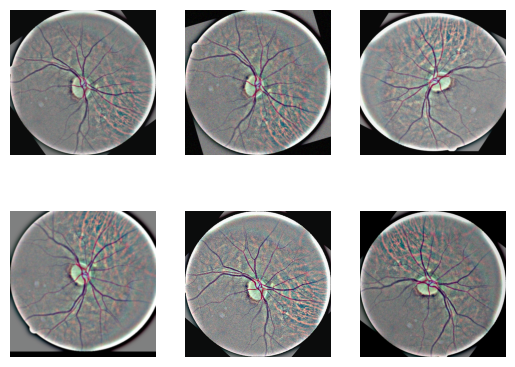

In [30]:
# Show transformed image (first image)
img = np.array(Image.open(f"/kaggle/input/datasets/jullopz/retinoplathy-detection-edited-v1/edited/{df_train_edited_full.iloc[0].image}.jpeg"))

for i in range(6):

    aug = train_transform(image=img)["image"]

    aug = aug.permute(1,2,0).numpy()

    aug = aug * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    plt.subplot(2,3,i+1)
    plt.imshow(np.clip(aug,0,1))
    plt.axis("off")

plt.show()

In [ ]:
# Create functions to transform the images
class RetinaDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        img_path = os.path.join(self.image_dir, self.df.iloc[idx]["image"] + ".jpeg")
        img = np.array(Image.open(img_path).convert("RGB"))
        label = self.df.iloc[idx]["level"]

        if self.transform:
            img = self.transform(image=img)["image"]

        return img, torch.tensor(label, dtype=torch.float32)

### Train - validation split by patient

On va faire un split train/validation pour entrainer notre modele ou on aura 80% des donnees sur train et 20% sur validation. Comme dit precedement, on veut que les deux images de chaque patient soient dans le meme group (train ou validation). Pour le faire on va utiliser un StratifiedGoupKFold avec 5 folds. On va aussi garder la meme distribution dans le deux groups train et validation.

In [ ]:
# Split train dataset into train and validation
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, valid_idx = next(
    sgkf.split(
        df_train_edited_full,
        y=df_train_edited_full["level"],          # stratify on the level
        groups=df_train_edited_full["patient_id"]  # never split a patient
    )
)

train_df_08 = df_train_edited_full.iloc[train_idx].reset_index(drop=True)
valid_df_02 = df_train_edited_full.iloc[valid_idx].reset_index(drop=True)

# Sanity checks: no patient in both sets, and similar level distributions
assert set(train_df_08["patient_id"]).isdisjoint(set(valid_df_02["patient_id"])), "Patient leakage!"

print(f"Train: {len(train_df_08)} images | Valid: {len(valid_df_02)} images")
print(pd.DataFrame({
    "train %": train_df_08["level"].value_counts(normalize=True).sort_index() * 100,
    "valid %": valid_df_02["level"].value_counts(normalize=True).sort_index() * 100,
}).round(2))

Train: 28100 images | Valid: 7026 images
       train %  valid %
level                  
0        73.36    73.94
1         7.03     6.65
2        15.08    15.00
3         2.51     2.39
4         2.01     2.02


## Model

In [34]:
# Define datasets to use
img_dir = "/kaggle/input/datasets/jullopz/retinoplathy-detection-edited-v1/edited"

train_dataset = RetinaDataset(
    train_df_08,
    image_dir = img_dir,
    transform=train_transform
)

valid_dataset = RetinaDataset(
    valid_df_02,
    image_dir = img_dir,
    transform=valid_transform
)
    

In [35]:
# Dataloaders
# Train data to load data to the model

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

# Validate data

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

In [ ]:
# Define model to use: EfficientNetV2-S pretrained on ImageNet (was efficientnet_b0)
model = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.IMAGENET1K_V1)

# 1 output (regression score) instead of 5 categories (classification).
# The classifier of EfficientNetV2 is also Sequential(Dropout, Linear), so index [1] is still the Linear layer.
NUM_OUTPUTS = 1
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_OUTPUTS)

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 159MB/s]


In [38]:
# Use CUDA to process the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

On a monte un modele base sur l'agorithme EfficientNet_V2_S. On va en suite dire comment le modele va s'entrainer. On va definir donc une fonction de perte MSE avec 10 epochs. L'idee c'est que le MSE penalise l'erreur par sa distance carre, donc on veut entrainer et minimiser ca a chaque iteration de notre modele

In [ ]:
#----------------
# new code, loss function MSE
#----------------

criterion = nn.MSELoss()

# update weights
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

# Define epochs
epochs = 10

# Mixed precision (float16) on GPU to speed up the bigger model
USE_AMP = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

In [ ]:
#----------------
# old code, model efficientnet_b0
#----------------

# Define model to use
#model = efficientnet_b0(weights="DEFAULT")

# Force only 5 categories
#model.classifier[1] = nn.Linear(model.classifier[1].in_features, 5)

#----------------
# old code, loss function cross entropy
#----------------

'''
# Define loss function
criterion = torch.nn.CrossEntropyLoss()

# update weights

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

# Define epochs
epochs = 10
'''

'\n# Define loss function\ncriterion = torch.nn.CrossEntropyLoss()\n\n# update weights\n\noptimizer = torch.optim.Adam(\n    model.parameters(),\n    lr=1e-4\n)\n\n# Define epochs\nepochs = 10\n'

Une chose presente dans notre modele c'est que la classification pour l'instant est faite de facon continue (continous scores). On a besoin de transformer ces valeurs continous en niveaux (0-4). Pour le faire on deux possibilites qu'on va tester:
1. QWK rounding: on va arrondir les valeurs et les mettre dans les 5 categories selon la categorie la plus proche
2. QWK distribution: on va suivre la distribution des classes qu'on a vu lors du premiere etape pour choisir dans quel categorie on classifie les continous scores obtenus

In [ ]:
# Helper functions to convert the continuous scores of the model into levels 0-4

NUM_LEVELS = 5

def scores_to_levels_by_rounding(scores):
    # Naive way: round the score and clip it to [0, 4]
    return np.clip(np.rint(scores), 0, NUM_LEVELS - 1).astype(int)


def scores_to_levels_by_distribution(scores, target_props):
    # CHANGE 4: assign the levels so that the predicted distribution equals target_props.
    # 1) sort the images from the lowest to the highest score
    # 2) the lowest X0% get level 0, the next X1% get level 1, ..., the highest X4% get level 4,
    #    where X0..X4 are the proportions of each level in the train set.
    scores = np.asarray(scores, dtype=float)
    n = len(scores)
    order = np.argsort(scores, kind="stable")                       # indices from lowest to highest score
    bounds = np.round(np.cumsum(target_props) * n).astype(int)      # cumulative number of images per level
    bounds[-1] = n                                                  # make sure every image gets a level
    levels = np.empty(n, dtype=int)
    start = 0
    for level, end in enumerate(bounds):
        levels[order[start:end]] = level
        start = end
    return levels


# Proportion of each level (0..4) in the train split, used for the validation
train_level_props = (
    train_df_08["level"].value_counts(normalize=True)
    .reindex(range(NUM_LEVELS), fill_value=0).values
)
print("Train level proportions:", np.round(train_level_props, 4))

# Proportion of each level in the FULL train set (35 126 images), used for the test predictions.
# Saved to a json file for further use.
full_train_level_props = (
    df_train_edited_full["level"].value_counts(normalize=True)
    .reindex(range(NUM_LEVELS), fill_value=0).values
)
with open("train_level_props.json", "w") as f:
    json.dump({
        "levels": list(range(NUM_LEVELS)),
        "counts": df_train_edited_full["level"].value_counts().reindex(range(NUM_LEVELS), fill_value=0).tolist(),
        "proportions": full_train_level_props.tolist(),
    }, f, indent=2)
print("Full train level proportions (saved to train_level_props.json):", np.round(full_train_level_props, 4))

Train level proportions: [0.7336 0.0703 0.1508 0.0251 0.0201]
Full train level proportions (saved to train_level_props.json): [0.7348 0.0695 0.1507 0.0249 0.0202]


Finalement, on va lancer l'entrainement du modele. On va suivre un loop de 10 epochs ou le modele va s'entrainer 10 fois dans toutes les batches a chaque epoch (en utiilisant le MSE loss, scale backward pass) et va evaluer les MSE loss + QWK, et en suite va garded les wieghts du modele de la meilleur distribution trouve.

In [ ]:
# To calculate best model (best weights)
best_valid_kappa = -1.0

print("Model started")
# Model run
for epoch in range(epochs):

# Training
    print("Started train", epoch)
    model.train()
    train_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # [ADDED] mixed precision forward pass
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            outputs = model(images).squeeze(1)

        # loss computed in float32 for numerical stability
        loss = criterion(outputs.float(), labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    train_loss = train_loss / len(train_loader)

# Validate
    print("Started validate", epoch)
    model.eval()
    valid_loss = 0
    valid_scores = []   # keep the predicted scores to compute the kappa
    valid_labels = []   

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                outputs = model(images).squeeze(1)   

            loss = criterion(outputs.float(), labels)

            valid_loss += loss.item()
            valid_scores.extend(outputs.float().cpu().numpy())   
            valid_labels.extend(labels.cpu().numpy().astype(int)) 

    valid_loss = valid_loss / len(valid_loader)

    # Quadratic weighted kappa on validation
    kappa_round = cohen_kappa_score(
        valid_labels, scores_to_levels_by_rounding(valid_scores), weights="quadratic")
    kappa_dist = cohen_kappa_score(
        valid_labels, scores_to_levels_by_distribution(valid_scores, train_level_props), weights="quadratic")

    print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f} | Valid Loss = {valid_loss:.4f} | "
          f"Valid QWK (rounding) = {kappa_round:.4f} | Valid QWK (train distribution) = {kappa_dist:.4f}")

    # save on best kappa with distribution matching (the method used for the submission)
    if kappa_dist > best_valid_kappa:

        best_valid_kappa = kappa_dist

        torch.save(
            model.state_dict(),
            "best_model.pth")

        print(f"New best model saved! Validation QWK = {kappa_dist:.4f}")

Model started
Started train 0
Started validate 0
Epoch 1: Train Loss = 0.5223 | Valid Loss = 0.3642 | Valid QWK (rounding) = 0.7327 | Valid QWK (train distribution) = 0.7611
New best model saved! Validation QWK = 0.7611
Started train 1
Started validate 1
Epoch 2: Train Loss = 0.4054 | Valid Loss = 0.3075 | Valid QWK (rounding) = 0.7891 | Valid QWK (train distribution) = 0.7916
New best model saved! Validation QWK = 0.7916
Started train 2
Started validate 2
Epoch 3: Train Loss = 0.3626 | Valid Loss = 0.3079 | Valid QWK (rounding) = 0.7926 | Valid QWK (train distribution) = 0.7923
New best model saved! Validation QWK = 0.7923
Started train 3
Started validate 3
Epoch 4: Train Loss = 0.3468 | Valid Loss = 0.3265 | Valid QWK (rounding) = 0.8090 | Valid QWK (train distribution) = 0.8038
New best model saved! Validation QWK = 0.8038
Started train 4
Started validate 4
Epoch 5: Train Loss = 0.3381 | Valid Loss = 0.3047 | Valid QWK (rounding) = 0.7866 | Valid QWK (train distribution) = 0.8122
Ne

**Results:**
| Epoch | Train loss | Valid loss | QWK rounding | QWK distribution |
|---|---|---|---|---|
| 1 | 0.5223 | 0.3642 | 0.7327 | 0.7611 ✔ |
| 2 | 0.4054 | 0.3075 | 0.7891 | 0.7916 ✔ |
| 3 | 0.3626 | 0.3079 | 0.7926 | 0.7923 ✔ |
| 4 | 0.3468 | 0.3265 | 0.8090 | 0.8038 ✔ |
| 5 | 0.3381 | 0.3047 | 0.7866 | 0.8122 ✔ |
| 6 | 0.3221 | 0.7430 | 0.8074 | 0.8090 |
| 7 | 0.3132 | 0.2741 | 0.8147 | 0.8173 ✔ |
| **8** | 0.3072 | 0.2818 | 0.8200 | **0.8219 ✔ (best)** |
| 9 | 0.2954 | 0.2828 | 0.8161 | 0.8200 |
| 10 | 0.2936 | 0.2957 | 0.7850 | 0.8188 |

(✔ = new best model saved)

Avec ces resultats, on peut constater que:
- La fonction de loss diminue rapidement entre les epochs. La validation QWK monte de 0.76 lors du premiere run a 0.821 dans le 8eme run
- QWK distribution donne des meilleurs resultats que QWK rounding dans 8 entre 10 runs. On voit que c'est aussi plus stable depuis l'epoch 5.
- The validation loss spike at epoch 6 (0.743) while the QWK stays high suggests a temporary shift in the scale of the scores (the ranking stays good, which distribution matching is insensitive to).
- Depuis l'epoch 8, le train loss diminue mais les metrics de validation ne s'ameliorent plus. cela indique que depuis cette epoque le modele commence a avoir overfitting

On choisis donc le meilleur modele a l'epoch 8. On va sauvegarder le weights et la distribution des donnees pour l'utiliser apres dans la prediction des images dans la prochaine etape.